In [1]:
from abc import ABCMeta, abstractmethod, abstractproperty
import enum

import numpy as np
np.set_printoptions(precision=3)
np.set_printoptions(suppress=True)

import pandas

import matplotlib.pyplot as plt
%matplotlib inline

## Bernoulli Bandit

We are going to implement several exploration strategies for simplest problem - bernoulli bandit.

The bandit has $K$ actions. Action produce 1.0 reward $r$ with probability $0 \le \theta_k \le 1$ which is unknown to agent, but fixed over time. Agent's objective is to minimize regret over fixed number $T$ of action selections:

$\rho = T\theta^* - \sum_{t=1}^T r_t$

Where $\theta^* = \max_k\{\theta_k\}$

**Real-world analogy:**

Clinical trials - we have $K$ pills and $T$ ill patient. After taking pill, patient is cured with probability $\theta_k$. Task is to find most efficient pill.

A research on clinical trials - https://arxiv.org/pdf/1507.08025.pdf

In [2]:
class BernoulliBandit:
    def __init__(self, n_actions=5):
        self._probs = np.random.random(n_actions)

    @property
    def action_count(self):
        return len(self._probs)

    def pull(self, action):
        if np.any(np.random.random() > self._probs[action]):
            return 0.0
        return 1.0

    def optimal_reward(self):
        """Used for regret calculation"""
        return np.max(self._probs)

    def step(self):
        """Used in nonstationary version"""
        pass

    def reset(self):
        """Used in nonstationary version"""

In [ ]:
class AbstractAgent(metaclass=ABCMeta):
    def init_actions(self, n_actions):
        initial_value = 1  # initial value to avoid devision by zero, when computing conversion rate (cvr)
        self._successes = np.zeros(n_actions) + initial_value
        self._failures = np.zeros(n_actions) + initial_value
        self._total_pulls = 2 * n_actions * initial_value # sum of initial values for successes and failures per each arm

    @abstractmethod
    def get_action(self):
        """
        Get current best actionf
        :rtype: int
        """
        pass

    def update(self, action, reward):
        """
        Observe reward from action and update agent's internal parameters
        :type action: int
        :type reward: int
        """
        self._total_pulls += 1
        if reward == 1:
            self._successes[action] += 1
        else:
            self._failures[action] += 1

    @property
    def name(self):
        return self.__class__.__name__


class RandomAgent(AbstractAgent):
    def get_action(self):
        return np.random.randint(0, len(self._successes))

### Epsilon-greedy agent [10 points]

**for** $t = 1,2,...$ **do**

&nbsp;&nbsp; **for** $k = 1,...,K$ **do**

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $\hat\theta_k \leftarrow \alpha_k / (\alpha_k + \beta_k)$

&nbsp;&nbsp; **end for** 

&nbsp;&nbsp; $x_t \leftarrow argmax_{k}\hat\theta$ with probability $1 - \epsilon$ or random action with probability $\epsilon$

&nbsp;&nbsp; Apply $x_t$ and observe $r_t$

&nbsp;&nbsp; $(\alpha_{x_t}, \beta_{x_t}) \leftarrow (\alpha_{x_t}, \beta_{x_t}) + (r_t, 1-r_t)$

**end for**

Implement the algorithm above in the cell below:

In [4]:
class EpsilonGreedyAgent(AbstractAgent):
    def __init__(self, epsilon=0.01):
        self._epsilon = epsilon

    def get_action(self):
        if np.random.rand() < self._epsilon:
            # do sth random
            return np.random.randint(0, len(self._successes))
        else:
            cvr = self._successes / (self._successes + self._failures)
            return np.argmax(cvr)

    @property
    def name(self):
        return self.__class__.__name__ + "(epsilon={})".format(self._epsilon)

### UCB Agent # [10 points]
Epsilon-greedy strategy heve no preference for actions. It would be better to select among actions that are uncertain or have potential to be optimal. One can come up with idea of index for each action that represents otimality and uncertainty at the same time. One efficient way to do it is to use UCB1 algorithm:

**for** $t = 1,2,...$ **do**

&nbsp;&nbsp; **for** $k = 1,...,K$ **do**

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; $w_k \leftarrow \alpha_k / (\alpha_k + \beta_k) + \sqrt{2log\ t \ / \ (\alpha_k + \beta_k)}$

&nbsp;&nbsp; **end for** 

&nbsp;&nbsp; **end for** 
 $x_t \leftarrow argmax_{k}w$

&nbsp;&nbsp; Apply $x_t$ and observe $r_t$

&nbsp;&nbsp; $(\alpha_{x_t}, \beta_{x_t}) \leftarrow (\alpha_{x_t}, \beta_{x_t}) + (r_t, 1-r_t)$

**end for**

__Note:__ in practice, one can multiply $\sqrt{2log\ t \ / \ (\alpha_k + \beta_k)}$ by some tunable parameter to regulate agent's optimism and wilingness to abandon non-promising actions.

More versions and optimality analysis - https://homes.di.unimi.it/~cesabian/Pubblicazioni/ml-02.pdf

In [5]:
class UCBAgent(AbstractAgent):
    def get_action(self):
        # Compute empirical means (expected success rate)
        mean = self._successes / (self._successes + self._failures)
        # Compute exploration bonus (uncertainty)
        bonus = np.sqrt(
            2 * np.log(self._total_pulls) / (self._successes + self._failures)
        )
        # Combine them
        w = mean + bonus
        # Choose the arm with the highest combined score
        return np.argmax(w)

### Thompson sampling [10 points]

UCB1 algorithm does not take into account actual distribution of rewards. If we know the distribution - we can do much better by using Thompson sampling:

**for** $t = 1,2,...$ **do**

&nbsp;&nbsp; **for** $k = 1,...,K$ **do**

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; Sample $\hat\theta_k \sim beta(\alpha_k, \beta_k)$

&nbsp;&nbsp; **end for** 

&nbsp;&nbsp; $x_t \leftarrow argmax_{k}\hat\theta$

&nbsp;&nbsp; Apply $x_t$ and observe $r_t$

&nbsp;&nbsp; $(\alpha_{x_t}, \beta_{x_t}) \leftarrow (\alpha_{x_t}, \beta_{x_t}) + (r_t, 1-r_t)$

**end for**
 

More on Thompson Sampling:
https://web.stanford.edu/~bvr/pubs/TS_Tutorial.pdf

In [6]:
class ThompsonSamplingAgent(AbstractAgent):
    def get_action(self):
        # Sample a theta value from Beta(alpha, beta) for each arm
        sampled_thetas = np.random.beta(self._successes, self._failures)
        # Choose the arm with the highest sampled theta
        return np.argmax(sampled_thetas)

# epsilon greedy with adaptive epsilon [10 points]
<YOUR CODE>

In [7]:
class AdaptiveEpsilonGreedyAgent(AbstractAgent):
    def __init__(self, epsilon_start=1.0, epsilon_min=0.01, decay_rate=0.001):
        """
        epsilon_start : initial epsilon value
        epsilon_min   : minimum epsilon (don’t decay below this)
        decay_rate    : rate of exponential decay
        """
        self._epsilon_start = epsilon_start
        self._epsilon_min = epsilon_min
        self._decay_rate = decay_rate
        self._total_pulls = 1  # ensure no divide-by-zero

    def get_action(self):
        # Compute decayed epsilon value (exponential decay)
        epsilon = max(
            self._epsilon_min,
            self._epsilon_start * np.exp(-self._decay_rate * self._total_pulls),
        )

        # Exploration vs exploitation decision
        if np.random.rand() < epsilon:
            return np.random.randint(0, len(self._successes))
        else:
            cvr = self._successes / (self._successes + self._failures)
            return np.argmax(cvr)

    def update(self, action, reward):
        """Update after each pull (and increment pull count)."""
        super().update(action, reward)
        self._total_pulls += 1

    @property
    def name(self):
        return f"{self.__class__.__name__}(start={self._epsilon_start}, min={self._epsilon_min}, decay={self._decay_rate})"

# optimistic initial value [10 points]

In [8]:
class OptimisticInitialValueAgent(AbstractAgent):
    def __init__(self, initial_success=10.0, initial_failure=1.0):
        """
        Initialize with optimistic prior values.
        initial_success : pseudo-success count (optimism level)
        initial_failure : pseudo-failure count
        """
        self._initial_success = initial_success
        self._initial_failure = initial_failure

    def init_actions(self, n_actions):
        """Override to use optimistic initialization."""
        self._successes = np.zeros(n_actions) + self._initial_success
        self._failures = np.zeros(n_actions) + self._initial_failure
        self._total_pulls = np.sum(self._successes + self._failures)

    def get_action(self):
        """Always choose the arm with the highest estimated success rate."""
        cvr = self._successes / (self._successes + self._failures)
        return np.argmax(cvr)

    @property
    def name(self):
        return f"{self.__class__.__name__}(init_s={self._initial_success}, init_f={self._initial_failure})"

# Regret

In [9]:
from collections import OrderedDict


def get_regret(env, agents, n_steps=5000, n_trials=50):
    scores = OrderedDict(
        {agent.name: [0.0 for step in range(n_steps)] for agent in agents}
    )

    for trial in range(n_trials):
        env.reset()

        for a in agents:
            a.init_actions(env.action_count)

        for i in range(n_steps):
            optimal_reward = env.optimal_reward()

            for agent in agents:
                action = agent.get_action()
                reward = env.pull(action)
                agent.update(action, reward)
                scores[agent.name][i] += optimal_reward - reward

            env.step()  # change bandit's state if it is unstationary

    for agent in agents:
        scores[agent.name] = np.cumsum(scores[agent.name]) / n_trials

    return scores


def plot_regret(agents, scores):
    for agent in agents:
        plt.plot(scores[agent.name])

    plt.legend([agent.name for agent in agents])

    plt.ylabel("regret")
    plt.xlabel("steps")

    plt.show()

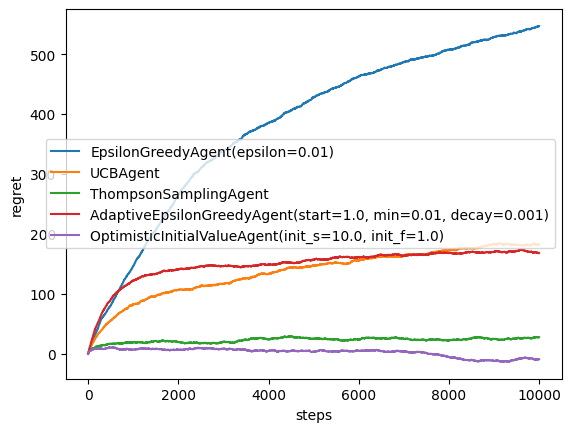

In [10]:
np.random.seed(3)

# Uncomment agents
agents = [
    EpsilonGreedyAgent(),
    UCBAgent(),
    ThompsonSamplingAgent(),
    # adaptive epsilone greedy agent
    AdaptiveEpsilonGreedyAgent(),
    # optimistial initial value agent
    OptimisticInitialValueAgent(),
]

regret = get_regret(BernoulliBandit(), agents, n_steps=10000, n_trials=10)
plot_regret(agents, regret)

# Theoretical Questions [50 points]

---

### **1. [10 points]**
Compute the expected regret of an **ε-greedy agent** with a fixed $\varepsilon$, given $n$ arms.

For an ε-greedy agent with fixed $ \varepsilon $ and $ n $ arms, the expected regret decomposes into:

**Regret = Exploration Regret + Exploitation Regret**

- **Exploration** (probability ε): uniform random arm selection
  - Expected regret: $\sum_{i=1}^n \frac{1}{n} \Delta_i = \bar{\Delta}$

- **Exploitation** (probability 1-ε): chooses optimal arm → regret = 0

**Expected regret per step:**

$
\mathbb{E}[r(t)] = \varepsilon \cdot \bar{\Delta} + (1 - \varepsilon) \cdot 0 = \varepsilon \bar{\Delta}
$

**Total expected regret after T steps:**

$
R(T) \approx \varepsilon \cdot T \cdot \bar{\Delta} = \frac{\varepsilon T}{n} \sum_{i=1}^n \Delta_i
$

**Key properties:**
- Linear regret growth: $R(T) = O(T)$.  
- No logarithmic reduction like UCB algorithms.  
- Smaller $\varepsilon$ reduces regret but slows exploration.  
- Regret depends proportionally on $\varepsilon$ and $\bar{\Delta}$.

---

### **2. [10 points]**
In the **UCB (Upper Confidence Bound)** algorithm, how would the agent’s behavior change if the exploration term is modified from $\log(t)$ to $t^{1/2}$?  
Would the agent favor **exploration** or **exploitation**?

Replacing $ \log(t) $ with $ t^{1/2} $ makes the agent explore **much more aggressively**.

- **Original UCB:** The bonus term is 

$
\sqrt{\frac{2 \log(t)}{n_k}}
$

which grows slowly and becomes negligible as arms are sampled.

- **Modified UCB:** The bonus term is

$
\sqrt{\frac{2 t^{1/2}}{n_k}} = \sqrt{\frac{2}{\sqrt{t} \cdot n_k}}
$

which grows faster in early stages.

**Behavioral changes:**
- Longer exploration phase since bonus stays large longer.
- Slower convergence to the optimal arm.
- More robustness to early estimation errors, reducing premature exploitation.

**Conclusion:** The agent prioritizes **exploration** over exploitation significantly more.

---

### **3. [10 points]**
In the **UCB algorithm**, how would the agent’s decision-making change if the confidence term is modified from $2 \cdot \log(t)$ to $4 \cdot \log(t)$?  
Interpret this change in terms of **increasing or decreasing the confidence interval** used for estimating the upper bound of action value estimates.

Increasing the coefficient in front of $ \log(t) $ makes the agent more **optimistic** and **explorative**.

$
\text{Original: } \hat{\mu} + \sqrt{\frac{2 \log(t)}{n_k}} \quad \to \quad \text{Modified: } \hat{\mu} + \sqrt{\frac{4 \log(t)}{n_k}} = \hat{\mu} + 2 \sqrt{\frac{\log(t)}{n_k}}
$

Effects:

- Greater optimism increases willingness to try uncertain arms.
- Exploration lasts longer due to wider confidence bounds.
- Less chance of discarding good arms early.
- May waste more time on clearly suboptimal arms.

This corresponds to a **wider confidence interval** and more exploration.

---

### **4. [10 points]**
In the **Thompson Sampling** algorithm, how would increasing the **initial value** to 100 affect the agent’s behavior?  
Would it favor **exploration** or **exploitation**?  
Interpret the initial values in terms of their role as **priors** for the **Beta distribution**.

Setting large initial values (e.g., 100) in Beta priors causes strong early **exploration**.

- The prior Beta($\alpha, \beta$) with large $\alpha, \beta$ is very concentrated around $\frac{\alpha}{\alpha + \beta}$.
- For $\alpha = \beta = 100$, prior mean = 0.5 with very low variance.

Behavioral consequences:

- Slow posterior updates; many samples required to dominate prior.
- Arms initially seem equally good, encouraging exploration.
- Early exploitation is reduced even if some arms show good performance.
- Converges smoothly, robust to early noise in observations.

Priors encode initial beliefs and affect how fast the agent learns.

---

### **5. [5 points]**
In the **ε-greedy algorithm**, if $\varepsilon$ is increased from $0.01$ to $0.1$, would the agent favor **exploration** or **exploitation**?

Increasing $\varepsilon$ from 0.01 to 0.1 means the agent explores **10 times more**.

- At $\varepsilon = 0.01$: 1% exploration, 99% exploitation.
- At $\varepsilon = 0.1$: 10% exploration, 90% exploitation.

Result: Significant increase in time spent exploring random arms, reducing time exploiting the best-known arm.

---

### **6. [5 points]**
Assuming an **infinite time horizon**, which algorithm(s) are **guaranteed to achieve the lowest average regret**, and why?

For infinite horizon, **Thompson Sampling** and **UCB** achieve the best asymptotic regret.

Reasons:

- Both have theoretical guarantees of logarithmic regret $ O(\log T) $ for stationary bandits.
- Lai & Robbins (1985) proved $ \Theta(\log T) $ is a lower bound on regret for any consistent policy.
- ε-Greedy exhibits linear regret $ O(\varepsilon T) $ due to constant exploration.
- Adaptive methods may improve constants but do not beat logarithmic regret order.

**Preferable choice:** Thompson Sampling often performs best in practice due to better constants and Bayesian approach, though both are asymptotically optimal.